# Lymph Data

In [1]:
from STalign import STalign
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import plotly
import requests
import scanpy as sc
import matplotlib
import os

import warnings
warnings.filterwarnings("ignore")

## Load Data

In [2]:
# load Merfish mouse brain 33 data
file_path = './lymph_data/11.h5ad'
file_path2 = './lymph_data/17.h5ad'

ad = sc.read(file_path)
ad_target = sc.read(file_path2)

In [3]:
cluster1 = ad.obs['original_clusters'].unique()
cluster2 = ad_target.obs['original_clusters'].unique()
all_clusters = set(cluster1).union(set(cluster2))
all_clusters

{'CAF',
 'CAM',
 'Cortex_CCL21',
 'Cytotoxic_IFN_signaling',
 'Fibroblasts',
 'Germinal_Center_Plasma_IgM_B_cell',
 'High_Endothelial_Venules',
 'M1_macrophages',
 'Macrophages',
 'Plasma_IgA',
 'Plasma_IgG',
 'T_cell',
 'Tumor',
 'Tumor_Keratin_Pearl',
 'unknown'}

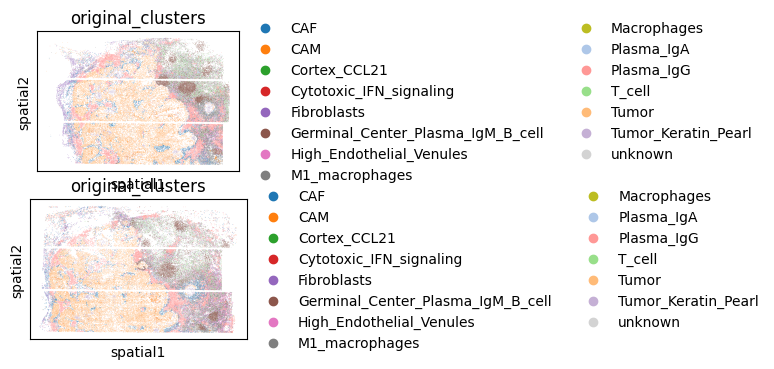

In [4]:
color_dict = {
    'CAF': '#1f77b4',  # Blue
    'CAM': '#ff7f0e',  # Orange
    'Cortex_CCL21': '#2ca02c',  # Green
    'Cytotoxic_IFN_signaling': '#d62728',  # Red
    'Fibroblasts': '#9467bd',  # Purple
    'Germinal_Center_Plasma_IgM_B_cell': '#8c564b',  # Brown
    'High_Endothelial_Venules': '#e377c2',  # Pink
    'M1_macrophages': '#7f7f7f',  # Gray
    'Macrophages': '#bcbd22',  # Olive
    'Mast_cells': '#17becf',  # Cyan
    'Plasma_IgA': '#aec7e8',  # Light Blue
    'Plasma_IgG': '#ff9896',  # Light Red
    'T_cell': '#98df8a',  # Light Green
    'Tumor': '#ffbb78',  # Peach
    'Tumor_Keratin_Pearl': '#c5b0d5',  # Lavender
    'unknown': '#d3d3d3'  # Light Gray (Neutral for unknown)
}

fig, axes = plt.subplots(2, 1, figsize=(6, 4))
sc.pl.spatial(ad, color='original_clusters', spot_size=30, ax=axes[0], palette=color_dict, show=False)
sc.pl.spatial(ad_target, color='original_clusters', spot_size=30, ax=axes[1], palette=color_dict, show=False)
plt.show()

0 of 70879
10000 of 70879
20000 of 70879
30000 of 70879
40000 of 70879
50000 of 70879
60000 of 70879
70000 of 70879
70878 of 70879


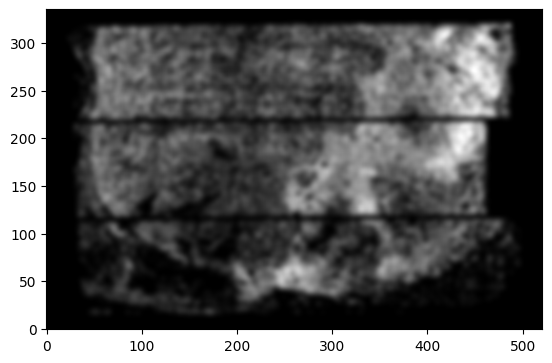

In [5]:
spatial_coords_target = ad_target.obsm['spatial']
x_target = spatial_coords_target[:, 0]
y_target = spatial_coords_target[:, 1]

# fig,ax = plt.subplots()

# rasterize at 30um resolution (assuming positions are in um units) and plot
XJ,YJ,J,fig = STalign.rasterize(x_target,y_target,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

0 of 67206
10000 of 67206
20000 of 67206
30000 of 67206
40000 of 67206
50000 of 67206
60000 of 67206
67205 of 67206


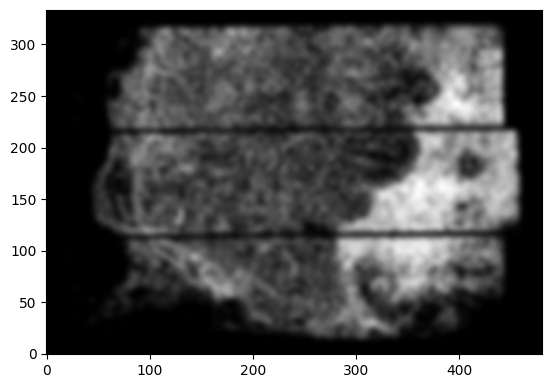

In [6]:
spatial_coords = ad.obsm['spatial']
x = spatial_coords[:, 0]
y = spatial_coords[:, 1]

# rasterize at 30um resolution (assuming positions are in um units) and plot
XI,YI,I,fig = STalign.rasterize(x,y,dx=30,blur=1.5)

# plot
ax = fig.axes[0]
ax.invert_yaxis()

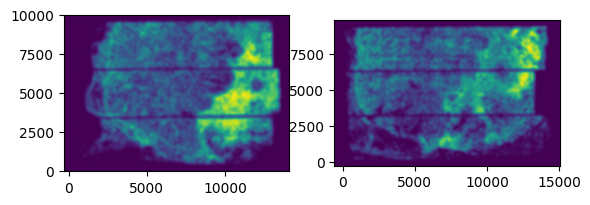

In [7]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow(I[0], extent=extentI)
ax[1].imshow(J[0], extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

In [9]:
np.savez('./npz_data/11', x=XI,y=YI,I=I)
np.savez('./npz_data/17', x=XJ,y=YJ,I=J)

In [26]:
# read from file
pointsIlist = np.load('./npz_data/11_curves.npy', allow_pickle=True).tolist()
print(pointsIlist)
pointsJlist = np.load('./npz_data/17_curves.npy', allow_pickle=True).tolist()
print(pointsJlist)

{'0': [(11959.944384522463, 5382.392461912086)], '1': [(11133.71051355472, 7709.8118167507955)], '2': [(2208.0572877482678, 6837.029558686279)]}
{'0': [(11091.986824223417, 6333.503645553529)], '1': [(9995.365856481481, 7984.737516521271)], '2': [(957.6965016427712, 7102.398806843852)]}


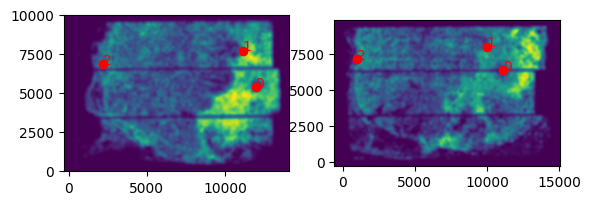

In [27]:
# convert to array
pointsI = []
pointsJ = []

# Jean's note: a bit odd to me that the points are stored as y,x
## instead of x,y but all downstream code uses this orientation
for i in pointsIlist.keys():
    pointsI.append([pointsIlist[i][0][1], pointsIlist[i][0][0]])
for i in pointsJlist.keys():
    pointsJ.append([pointsJlist[i][0][1], pointsJlist[i][0][0]])

pointsI = np.array(pointsI)
pointsJ = np.array(pointsJ)

# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
fig,ax = plt.subplots(1,2)
ax[0].imshow((I.transpose(1,2,0).squeeze()), extent=extentI) # just want 201x276 matrix
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ) # just want 201x276 matrix
# with points
ax[0].scatter(pointsI[:,1], pointsI[:,0], c='red')
ax[1].scatter(pointsJ[:,1], pointsJ[:,0], c='red')
for i in range(pointsI.shape[0]):
    ax[0].text(pointsI[i,1],pointsI[i,0],f'{i}', c='red')
    ax[1].text(pointsJ[i,1],pointsJ[i,0],f'{i}', c='red')
ax[0].invert_yaxis()
ax[1].invert_yaxis()

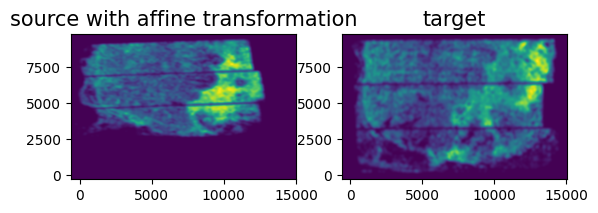

In [28]:
# set device for building tensors
if torch.cuda.is_available():
    torch.set_default_device('cuda:0')
else:
    torch.set_default_device('cpu')

# compute initial affine transformation from points
L,T = STalign.L_T_from_points(pointsI, pointsJ)
A = STalign.to_A(torch.tensor(L),torch.tensor(T))

# compute initial affine transformation from points
AI = STalign.transform_image_source_with_A(A, [YI,XI], I, [YJ,XJ])

#switch tensor from cuda to cpu for plotting with numpy
if AI.is_cuda:
    AI = AI.cpu()

fig,ax = plt.subplots(1,2)
ax[0].imshow((AI.permute(1,2,0).squeeze()), extent=extentJ)
ax[1].imshow((J.transpose(1,2,0).squeeze()), extent=extentJ)

ax[0].set_title('source with affine transformation', fontsize=15)
ax[1].set_title('target', fontsize=15)

ax[0].invert_yaxis()
ax[1].invert_yaxis()

CPU times: user 16min 28s, sys: 16.1 s, total: 16min 45s
Wall time: 17min 9s


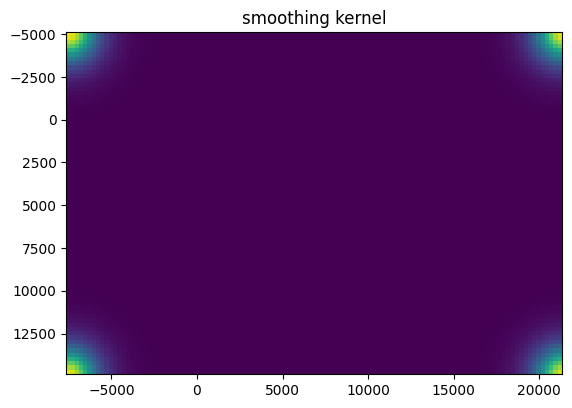

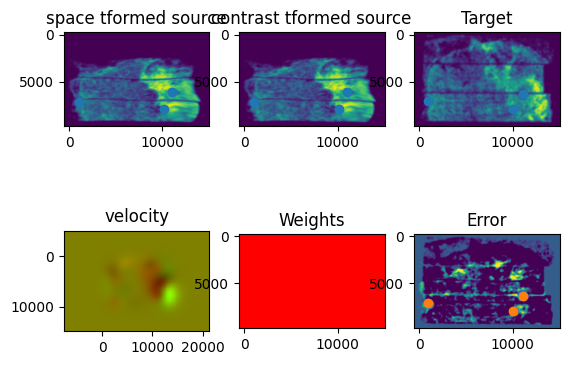

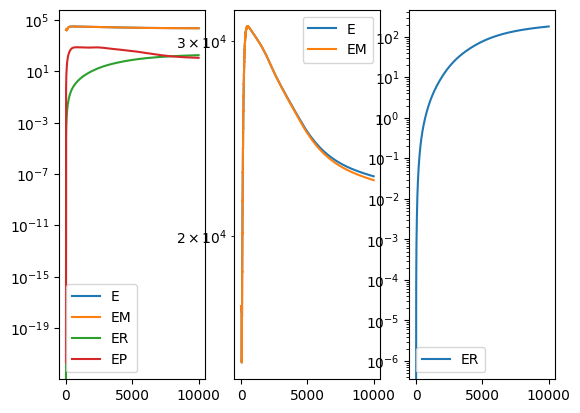

In [29]:
%%time
# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
            'pointsI':pointsI,
            'pointsJ':pointsJ,
            'L':L,'T':T,
            'niter':10000,
            'device':device,
            'epV': 20,
            'sigmaA': 0.5, #standard deviation of artifact intensities
            'sigmaB': 0.5, #standard deviation of background intensities
            'sigmaM': 0.5, #standard deviation of matching tissue intenities
          }

out = STalign.LDDMM([YI,XI],I,[YJ,XJ],J,**params)

In [30]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']

In [31]:
pointsI = torch.tensor(np.stack([y, x], 1), device='cuda', dtype=torch.float64)

# apply transform to original points
tpointsI= STalign.transform_points_source_to_target(xv,v,A, pointsI)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

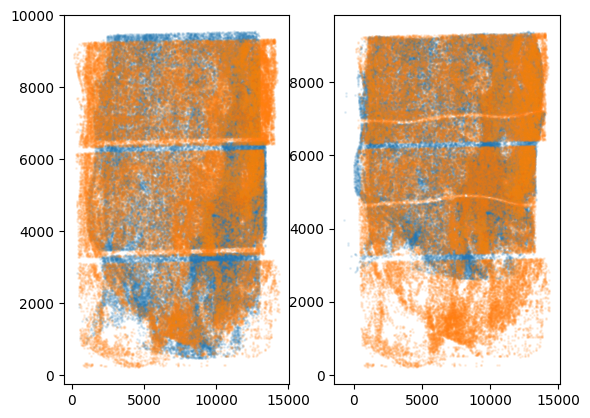

In [32]:
fig,ax = plt.subplots(1,2)
ax[0].scatter(x,y,s=1,alpha=0.1, label='source with initial affine transformation')
ax[0].scatter(x_target,y_target,s=1,alpha=0.1, label='target')
ax[1].scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.1, label = 'source STaligned')
ax[1].scatter(x_target,y_target,s=1,alpha=0.1, label='target')
# ax[0].legend(markerscale = 10, loc = 'lower left')
# ax[1].legend(markerscale = 10, loc = 'lower left')

## LAA & ARI

In [33]:
from scipy.spatial import cKDTree
from sklearn.metrics import adjusted_rand_score


def find_nearest_points(f1, f2):
    """
    Find the nearest point in f2 for each point in f1 using batch processing.
    
    Args:
        f1 (numpy.ndarray): Array of shape (n_points_1, 2) representing points in f1.
        f2 (numpy.ndarray): Array of shape (n_points_2, 2) representing points in f2.
        batch_size (int): Number of points to process in each batch.
        
    """
    # Build a k-d tree for f2
    tree = cKDTree(f2)
    
    # Query the k-d tree for nearest neighbors of points in f1
    distances, nearest_indices = tree.query(f1)
        
    cnt = 0
    true_clusters_mapped_region = []
    mapped_clusters_mapped_region = []

    for i in range(len(f1)):
        f1_cluster = ad_target.obs.iloc[i]['original_clusters']
        f2_cluster = ad.obs.iloc[nearest_indices[i]]['original_clusters']
        true_clusters_mapped_region.append(f1_cluster)
        mapped_clusters_mapped_region.append(f2_cluster)
        if f1_cluster == f2_cluster:
            cnt += 1 

    laa = cnt/len(f2)
    ari = adjusted_rand_score(true_clusters_mapped_region, mapped_clusters_mapped_region)
              
    return laa,ari


In [34]:
f1 = np.column_stack((x_target, y_target))  # Shape: (n_points, 2)
f2 = np.column_stack((xI_LDDMM, yI_LDDMM))  # Shape: (n_points, 2)

laa,ari = find_nearest_points(f1, f2)

print(laa)
print(ari)

0.325938160283308
0.15945996757051478


## 3D

In [35]:
dfs = ad.obs['original_clusters']
df1 = dfs.reset_index()
df1.head()

,index,original_clusters
0,11_466,Tumor
1,11_990,Tumor
2,11_1040,CAF
3,11_1063,unknown
4,11_1611,Plasma_IgG


In [36]:
df3_1 = pd.DataFrame(
    {
        "X": xI_LDDMM,
        "Y": yI_LDDMM,
    },
)

results1 = pd.concat([df1, df3_1], axis=1)
results1['Z'] = 7
results1['slice'] = '11'
results1

,index,original_clusters,X,Y,Z,slice
0,11_466,Tumor,-699.404563,4240.956698,7,11
1,11_990,Tumor,-449.627344,3600.800463,7,11
2,11_1040,CAF,-442.292683,3551.093076,7,11
3,11_1063,unknown,-640.976977,7185.435478,7,11
4,11_1611,Plasma_IgG,-283.128825,2915.431857,7,11
...,...,...,...,...,...,...
67201,11_171732,Germinal_Center_Plasma_IgM_B_cell,13354.206508,6046.348249,7,11
67202,11_171746,M1_macrophages,13313.814294,5192.964246,7,11
67203,11_171748,M1_macrophages,13293.839064,5892.113790,7,11
67204,11_171749,M1_macrophages,13304.946093,5920.008808,7,11


In [37]:
results1.to_csv("11.csv", index=False)